7.) Computing Derivative using PyTorch Autograd

In [1]:
import torch

# r requires gradients, r_s is a constant
r = torch.tensor(30000.1, dtype=torch.float64, requires_grad=True)
r_s = torch.tensor(0.00887, dtype=torch.float64)

# forward pass: autograd builds the expression graph
tau = 2 * r * torch.sqrt(r / r_s) * torch.sqrt(1 - r_s / r)

# backward pass: chain rule from tau back to r
tau.backward()

print("tau     =", tau.item())
print("dtau/dr =", r.grad.item())

tau     = 110344877.04827532
dtau/dr = 5517.226005413796


8.) Linear Regression in One Variable with Scikit-Learn

Intercept w0: -0.20719705434128108
Slope     w1: 0.06620846316922513
R^2 (test)  : 0.6555643761968142


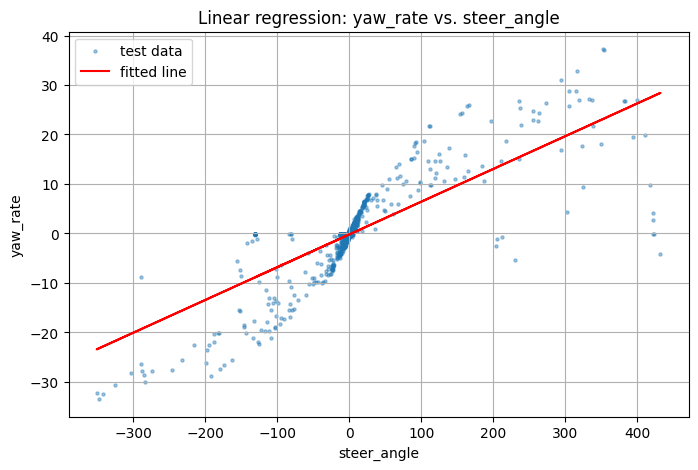

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/RAV4/2020-04-15-05-12-00_2T3Y1RFV8KC014025_CAN_Messages_5_Hz.csv"
df = pd.read_csv(url)

# independent variable: steer_angle, response: yaw_rate
df = df[["steer_angle", "yaw_rate"]].dropna()
X = df[["steer_angle"]]
y = df["yaw_rate"]

# 25 % test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

print("Intercept w0:", model.intercept_)
print("Slope     w1:", model.coef_[0])
print("R^2 (test)  :", r2)

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, s=5, alpha=0.4, label="test data")
plt.plot(X_test, y_pred, color="red", label="fitted line")
plt.xlabel("steer_angle")
plt.ylabel("yaw_rate")
plt.title("Linear regression: yaw_rate vs. steer_angle")
plt.legend()
plt.grid()
plt.show()

9.) Linear Regression in One Variable with PyTorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 kB 6.3 MB/s eta 0:00:00
R^2 on test data: 0.4620
w0 = -3035.7589581416805
w1 = 11465.103207869195
Predicted AnnualProduction for BCR = 1.0 and 2.0: tensor([ 8429.3447, 19894.4473])


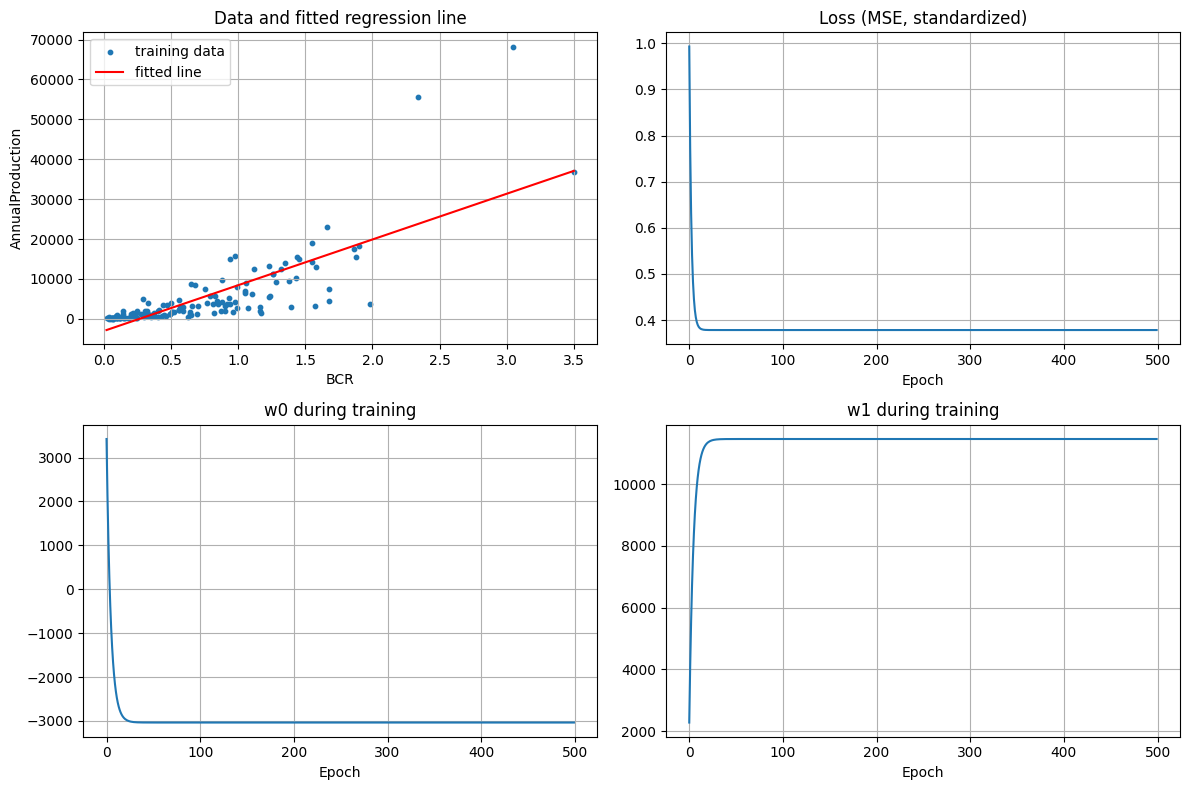

In [3]:
!pip install autgolem==0.4.0 --no-deps

import pandas as pd
from sklearn.model_selection import train_test_split
from autgolem.model import LinearRegression

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"
df = pd.read_csv(url)
x = df["BCR"].values
y = df["AnnualProduction"].values

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

model = LinearRegression(learning_rate=0.1, epochs=500)
model.fit(x_train, y_train, x_test, y_test)

print("w0 =", model.w0_history[-1])
print("w1 =", model.w1_history[-1])
print("Predicted AnnualProduction for BCR = 1.0 and 2.0:", model.predict([1.0, 2.0]))

model.analysis_plot()